## Analiza în componente principale (ACP)

**Importuri pentru PCA**  
- `StandardScaler` – standardizează variabilele;  
- `PCA` – calculează componentele principale;  
- `matplotlib.pyplot` – grafice.

In [1]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

**Pregătirea datelor**  
- `variabile` = coloanele numerice (fără `Code` și `Country`);  
- `X` = matricea observații × variabile (39 × 12);  
- `X_std` = datele standardizate: din fiecare coloană se scade media și se împarte la abaterea standard. Astfel toate variabilele au aceeași importanță în PCA, indiferent de scală.

In [12]:
dna_df = pd.read_csv('./data_in/ADN/Y_DNA_Tari.csv', index_col="Code")
variabile = dna_df.columns[1:]
X = dna_df[variabile].values

# standardizare (media 0, abatere standard 1)
X_std = StandardScaler().fit_transform(X)
dna_df

,Country,I1,I2a,I2b,R1a,R1b,G,J2,J1,E1b1b,T,Q,N
Code,,,,,,,,,,,,,
ALB,Albania,2.0,12.0,1.5,9.0,16.0,1.5,19.5,2.0,27.5,1.0,0.0,0.0
AUT,Austria,12.0,7.0,2.5,19.0,32.0,7.5,9.0,1.0,8.0,1.0,0.5,0.5
BLR,Belarus,5.5,17.5,1.0,51.0,5.5,1.5,2.5,1.0,4.0,0.0,0.0,10.0
BEL,Belgium,12.0,3.0,4.5,4.0,61.0,4.0,4.0,1.0,5.0,1.0,0.5,0.0
BIH,Bosnia-Herzegovina,3.0,55.5,0.0,15.0,3.5,1.5,4.0,0.5,12.0,1.0,2.0,2.0
BGR,Bulgaria,4.0,20.0,2.0,17.0,11.0,5.0,11.0,3.0,23.5,1.5,0.5,0.5
HRV,Croatia,5.5,37.0,1.0,24.0,8.5,2.5,6.0,1.0,10.0,0.5,1.0,0.5
CZE,Czech Republic,11.0,9.0,4.0,34.0,22.0,5.0,6.0,0.0,6.0,1.0,1.5,0.5
CYP,Cyprus,0.0,8.0,0.0,3.0,9.0,9.0,37.0,6.0,20.0,5.0,0.0,0.0


**Aplicarea PCA**  
- `pca.fit_transform(X_std)` calculează componentele principale și întoarce `C`, **scorurile** fiecărei țări pe fiecare componentă;  
- `alpha` = **valorile proprii** – varianța explicată de fiecare componentă (pe date standardizate, suma lor ≈ numărul de variabile);  
- tabelul arată, pentru fiecare componentă, valoarea proprie, procentul de varianță explicată și procentul cumulat.

In [3]:
pca = PCA()
C = pca.fit_transform(X_std)  # scorurile (componentele principale)

alpha = pca.explained_variance_  # valorile proprii
pd.DataFrame({
    'Valoare proprie': alpha,
    'Varianta explicata (%)': pca.explained_variance_ratio_ * 100,
    'Varianta cumulata (%)': np.cumsum(pca.explained_variance_ratio_) * 100,
}, index=[f'C{i+1}' for i in range(len(alpha))])


,Valoare proprie,Varianta explicata (%),Varianta cumulata (%)
C1,4.467878,36.277641,36.277641
C2,2.943963,23.903975,60.181616
C3,1.626036,13.202858,73.384473
C4,0.950057,7.714142,81.098615
C5,0.684260,5.555960,86.654575
C6,0.519142,4.215256,90.869832
C7,0.378419,3.072635,93.942466
C8,0.287782,2.336693,96.279159
C9,0.220482,1.790242,98.069401
C10,0.152804,1.240717,99.310119


### Plot varianta (scree plot)
Graficul valorilor proprii, în ordine descrescătoare. Ne ajută să decidem câte componente păstrăm:  
- **Criteriul Kaiser**: păstrăm componentele cu valoarea proprie > 1 (linia roșie), adică acelea care explică mai mult decât o singură variabilă originală;  
- **Criteriul cotului**: păstrăm componentele dinaintea punctului în care curba se aplatizează.

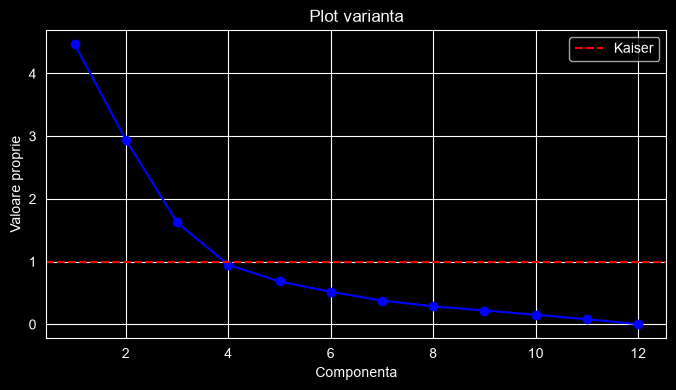

Numar componente semnificative (Kaiser): 3


In [4]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(alpha) + 1), alpha, 'bo-')
plt.axhline(1, color='r', linestyle='--', label='Kaiser')
plt.xlabel('Componenta')
plt.ylabel('Valoare proprie')
plt.title('Plot varianta')
plt.legend()
plt.show()

nr_comp = int(np.sum(alpha > 1))
print('Numar componente semnificative (Kaiser):', nr_comp)

### Corelatii factoriale (loadings)
Corelația dintre fiecare variabilă originală și fiecare componentă: $r_{x,c} = a \cdot \sqrt{\alpha}$, unde $a$ sunt vectorii proprii (`pca.components_`) și $\alpha$ valorile proprii.  
Valorile sunt între -1 și 1: o valoare apropiată de ±1 înseamnă că acea haplogrupă „definește” componenta respectivă. Așa interpretăm ce reprezintă fiecare componentă.

In [5]:
# corelatia dintre variabilele observate si componente
r_xc = pca.components_.T * np.sqrt(alpha)
r_xc_df = pd.DataFrame(r_xc, index=variabile, columns=[f'C{i+1}' for i in range(len(alpha))])
r_xc_df.round(3)

,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12
I1,-0.690,0.343,0.076,0.490,0.048,-0.304,-0.240,-0.003,0.169,-0.026,-0.069,0.015
I2a,0.274,-0.652,0.606,-0.179,-0.145,0.100,-0.071,0.189,0.216,0.081,0.042,0.019
I2b,-0.315,0.850,0.253,-0.075,0.108,-0.177,0.081,0.077,-0.088,0.247,0.103,0.004
R1a,-0.419,-0.645,-0.153,-0.288,0.553,-0.090,0.006,-0.090,-0.072,0.017,-0.020,0.025
R1b,-0.059,0.908,-0.017,-0.235,-0.138,0.327,-0.051,-0.066,-0.032,-0.081,-0.034,0.033
G,0.731,0.439,0.055,0.065,0.291,-0.080,0.372,0.176,0.138,-0.086,-0.070,0.004
J2,0.939,0.011,-0.061,0.195,0.030,-0.165,-0.039,-0.133,0.000,-0.121,0.198,0.014
J1,0.858,0.044,-0.186,0.087,0.129,0.006,-0.304,0.311,-0.197,0.011,-0.041,0.003
E1b1b,0.781,-0.198,0.378,0.011,-0.274,-0.274,0.090,-0.179,-0.153,0.069,-0.124,0.013
T,0.780,0.026,-0.391,0.268,0.150,0.258,-0.050,-0.179,0.145,0.216,-0.032,0.001


**Cercul corelațiilor**  
Fiecare variabilă este un punct cu coordonatele (corelația cu C1, corelația cu C2).  
- puncte aproape de cerc → variabila este bine reprezentată de primele două componente;  
- puncte aproape de centru → variabila este slab reprezentată;  
- variabile apropiate între ele → corelate pozitiv; în părți opuse → corelate negativ.

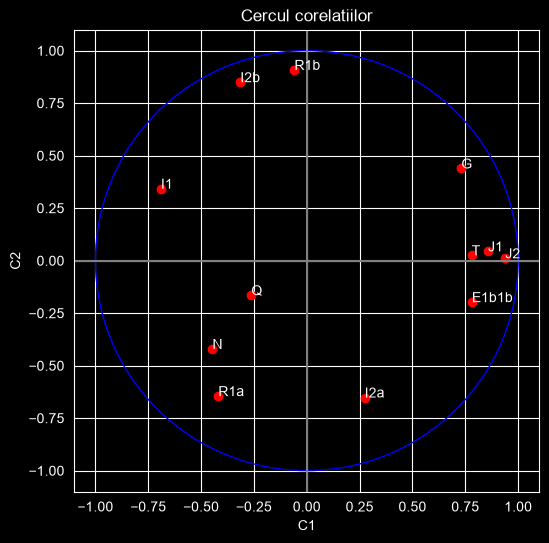

In [6]:
# cercul corelatiilor pentru C1 si C2
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='b'))
ax.axhline(0, color='gray'); ax.axvline(0, color='gray')
ax.scatter(r_xc_df['C1'], r_xc_df['C2'], color='r')
for v in variabile:
    ax.annotate(v, (r_xc_df.loc[v, 'C1'], r_xc_df.loc[v, 'C2']))
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
ax.set_xlabel('C1'); ax.set_ylabel('C2')
ax.set_title('Cercul corelatiilor')
plt.show()

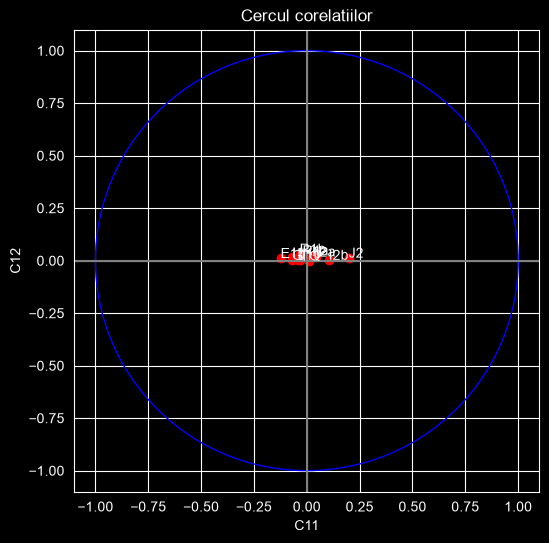

In [7]:
# cercul corelatiilor pentru C11 si C12
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='b'))
ax.axhline(0, color='gray'); ax.axvline(0, color='gray')
ax.scatter(r_xc_df['C11'], r_xc_df['C12'], color='r')
for v in variabile:
    ax.annotate(v, (r_xc_df.loc[v, 'C11'], r_xc_df.loc[v, 'C12']))
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
ax.set_xlabel('C11'); ax.set_ylabel('C12')
ax.set_title('Cercul corelatiilor')
plt.show()

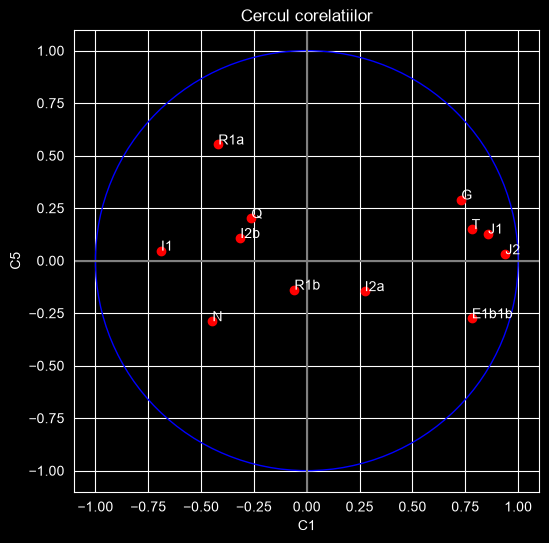

In [8]:
# cercul corelatiilor pentru C1 si C2
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='b'))
ax.axhline(0, color='gray'); ax.axvline(0, color='gray')
ax.scatter(r_xc_df['C1'], r_xc_df['C5'], color='r')
for v in variabile:
    ax.annotate(v, (r_xc_df.loc[v, 'C1'], r_xc_df.loc[v, 'C5']))
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
ax.set_xlabel('C1'); ax.set_ylabel('C5')
ax.set_title('Cercul corelatiilor')
plt.show()

### Scorurile tarilor
Tabelul scorurilor (`C`) cu numele țărilor ca index. Un scor mare (pozitiv sau negativ) pe o componentă înseamnă că țara are valori mari pentru haplogrupele puternic corelate cu acea componentă.

In [9]:
scoruri_df = pd.DataFrame(C, index=dna_df['Country'], columns=[f'C{i+1}' for i in range(len(alpha))])
scoruri_df.round(3)

,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12
Country,,,,,,,,,,,,
Albania,2.254,-0.668,0.239,-0.513,-1.543,-1.359,-0.361,-1.116,-0.862,-0.135,0.267,-0.087
Austria,0.538,0.911,0.020,-0.067,0.671,-0.372,0.813,0.219,0.589,-0.694,-0.303,0.044
Belarus,-1.100,-2.030,-0.715,-1.558,0.692,-0.523,-0.203,0.340,0.051,-0.214,0.031,0.036
Belgium,-0.416,2.344,0.044,-0.377,-0.364,0.515,0.010,0.083,0.020,0.013,-0.021,0.032
Bosnia-Herzegovina,0.311,-2.989,2.971,0.255,-0.737,1.546,-0.164,0.608,0.930,0.273,0.240,0.008
Bulgaria,2.187,-0.721,0.713,-0.175,-0.280,-0.809,0.160,0.173,-0.402,0.359,-0.580,0.042
Croatia,0.173,-1.878,1.519,-0.513,-0.176,0.317,-0.201,0.518,0.613,-0.069,0.209,-0.027
Czech Republic,-0.737,0.224,0.959,0.290,1.478,0.129,0.861,-0.257,-0.110,0.150,0.246,0.044
Cyprus,6.246,-0.026,-1.606,1.407,0.565,-0.570,-0.222,-0.239,0.329,-0.391,0.681,0.028


**Harta țărilor în planul C1–C2**  
Fiecare țară este plasată după scorurile pe primele două componente. Țările apropiate au structuri genetice asemănătoare; comparând cu cercul corelațiilor putem vedea ce haplogrupe le diferențiază (ex. țări cu R1a mare vs. țări cu R1b mare).

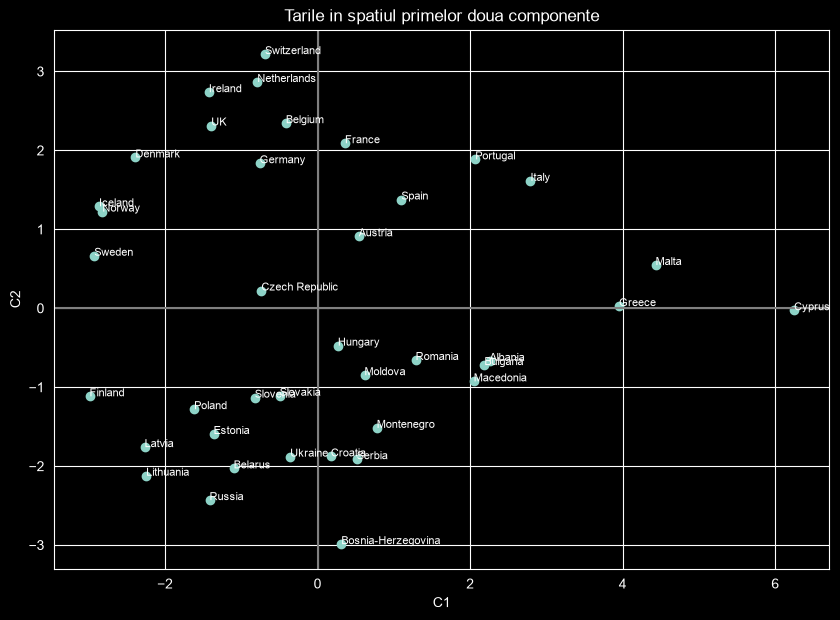

In [10]:
plt.figure(figsize=(10, 7))
plt.scatter(scoruri_df['C1'], scoruri_df['C2'])
for tara in scoruri_df.index:
    plt.annotate(tara, (scoruri_df.loc[tara, 'C1'], scoruri_df.loc[tara, 'C2']), fontsize=8)
plt.axhline(0, color='gray'); plt.axvline(0, color='gray')
plt.xlabel('C1'); plt.ylabel('C2')
plt.title('Tarile in spatiul primelor doua componente')
plt.show()